# Model 5 — Gradient Boosting
**IT2011 AIML · Progress Review II · Member: `<Student ID>`**

**Problem:** predict `next_risk_class` — whether the patient's *next* glucose reading will be
Hypoglycemic, Normal or Hyperglycemic — from the current reading and its context.

**Data:** the train/test split produced by `Project_preprocessing_eda_pipeline.ipynb`
(`processed_dataset_train.csv` / `processed_dataset_test.csv`), the split reviewed in Progress Review I. Three known issues are handled in this notebook, exactly as in Models 1–4:
1. `daily_total_insulin` is the *whole day's* insulin total, so it includes doses given after the reading
   (future information). It is **dropped**. The pipeline's PC1–PC17 columns were computed with it included, so they
   are **not used**; PCA is re-fit inside the model pipeline on the clean features (Section 1).
2. `reading_index` is **excluded** from the features. It is the reading's position in the patient's record, not a
   physiological measurement, and it partly identifies which patient a reading comes from (evidence below). In a
   training-set audit removing it raised hypo recall on *future* readings for every model tried.
3. The split is **row-wise**: the same 70 patients appear in both train and test. The split is kept, and Section 10
   adds two validation checks — **time-ordered** validation for already-monitored patients (the use case) and
   **GroupKFold** as the unseen-patient generalisation check.

**Use case:** predict the next reading for patients who are **already being monitored**. The features
(`prev_glucose`, `rolling_mean_3`, `rolling_std_3`, `hours_since_prev`) need the patient's earlier
readings, so the model only applies once someone's glucose is being tracked.

**Metrics — two different roles (same as Models 1–4, so the models can be compared):**
- **Tuning metric: balanced accuracy.** It is what GridSearchCV maximises (Section 3 explains why).
- **Key reported metric: hypo recall.** A missed hypo event (false negative) is the most dangerous error, so it is
  the number to watch — but it cannot be the tuning metric on its own, because a model that flags everything as
  hypo would win.

**What is different from Model 3 (Random Forest):** a forest grows many trees *independently* and averages them.
Gradient boosting grows its trees *one after another*, each small tree fitted to the mistakes of all the trees before
it, and adds them up with a small step (the learning rate). That usually gives more accurate models on tabular data,
but unlike a forest, **adding more trees can make it overfit**, so the number of rounds, the learning rate and the tree
depth have to be tuned together.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import FeatureUnion, make_pipeline as sk_make_pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, GroupKFold, cross_validate
from sklearn.metrics import (make_scorer, fbeta_score, recall_score, precision_score, f1_score, accuracy_score,
                             balanced_accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, roc_curve, get_scorer)
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

from imblearn.pipeline import Pipeline          # imblearn Pipeline: resampling happens only on training folds
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

RANDOM_STATE = 42

## 1. Load the train/test split and define the feature sets
Three **preprocessing varieties** of the input features are compared:

| Feature set | What the model sees | Idea |
|---|---|---|
| `original` | the 21 engineered/encoded features | every feature keeps its clinical meaning |
| `pca` | principal components of those 21 features (95% of variance) | decorrelated, fewer dimensions |
| `all` | the 21 features **plus** their principal components | what the pipeline outputs by default |

**PCA is re-fit inside the model pipeline.** The pipeline's PC1–PC17 columns were computed from a feature set that
included the leaky `daily_total_insulin`, so they are not used. The same method as the preprocessing pipeline — a
separate `StandardScaler` followed by PCA keeping 95% of the variance — is applied to the 21 clean features as a
pipeline step, so it is fit **on the training folds only** in every cross-validation split.

In [2]:
train = pd.read_csv("../results/outputs/processed_dataset_train.csv")
test  = pd.read_csv("../results/outputs/processed_dataset_test.csv")
print("train:", train.shape, " test:", test.shape)

TARGET = "next_risk_class"
NON_FEATURES = ["patient_id", "timestamp", "date", "time", "code", "code_description",
                "risk_class",           # current band - circular with glucose_mg_dl
                "next_glucose",         # the next reading itself - would leak the answer
                "daily_total_insulin",  # whole-day total - includes insulin given AFTER this reading
                "reading_index",        # position in the patient's record - not physiology (see Section 8/10 evidence)
                TARGET]

PIPELINE_PCS = [c for c in train.columns if c.startswith("PC")]   # computed with the leaky column - not used
FEATURES = [c for c in train.columns if c not in NON_FEATURES and c not in PIPELINE_PCS]
print(f"{len(FEATURES)} clean input features (pipeline PC columns excluded: {len(PIPELINE_PCS)})")
print(FEATURES)

y_train, y_test = train[TARGET], test[TARGET]
groups_train = train["patient_id"]

print("\nClass distribution (train):")
print(y_train.value_counts(normalize=True).round(3))

train: (10635, 49)  test: (2659, 49)
21 clean input features (pipeline PC columns excluded: 17)
['hour', 'is_weekend', 'glucose_mg_dl', 'prev_glucose', 'hours_since_prev', 'rolling_mean_3', 'rolling_std_3', 'insulin_regular_6h', 'insulin_nph_6h', 'insulin_ultralente_6h', 'meals_6h', 'exercise_6h', 'hypo_symptoms_6h', 'dow_sin', 'dow_cos', 'ctx_post_meal', 'ctx_pre_breakfast', 'ctx_pre_lunch', 'ctx_pre_snack', 'ctx_pre_supper', 'ctx_unspecified']

Class distribution (train):
next_risk_class
Normal           0.523
Hyperglycemic    0.361
Hypoglycemic     0.116
Name: proportion, dtype: float64


In [3]:
# Evidence for dropping daily_total_insulin: it has ONE value per patient per day, even on days with several
# readings - so a morning reading already "knows" the evening's doses.
per_day = train.groupby(["patient_id", "date"])["daily_total_insulin"].nunique()
readings = train.groupby(["patient_id", "date"]).size()
print("patient-days with a single daily_total_insulin value:", f"{(per_day == 1).mean():.1%}")
print("...of which have more than one reading that day     :", f"{(readings[per_day == 1] > 1).mean():.1%}")

patient-days with a single daily_total_insulin value: 100.0%
...of which have more than one reading that day     : 89.4%


## 2. Why Gradient Boosting suits this problem
- **It builds on the strength of trees.** Like the single tree and the forest, it needs no feature scaling and can
  represent thresholds, interactions and the U-shaped glucose pattern that a linear model cannot.
- **It corrects its own mistakes.** Each new small tree is fitted to the errors the ensemble still makes, so the model
  keeps improving where it is wrong. The **learning rate** shrinks each tree's contribution, which makes the
  improvement gradual and less prone to overfit.
- **Often the strongest tabular model.** Boosting is often among the most accurate tree-based methods when it is
  tuned, which is why it is a natural last tree model to try; how it compares here is shown in the group comparison.
- **Which implementation.** `HistGradientBoostingClassifier` bins every feature into at most 255 buckets, which makes
  it much faster than the older `GradientBoostingClassifier`, and it supports `class_weight`, so the same four imbalance
  strategies can be used as for every other model. With three classes it grows three trees per round.
- **Weakness — it can overfit with more rounds.** A forest never gets worse with more trees, but a boosted model
  keeps fitting the training data and eventually fits its noise. The number of rounds (`max_iter`) is tuned and
  checked with a rounds experiment in Section 6.
- **Weakness — less readable.** There are hundreds of small trees and no rules to read, and scikit-learn gives no
  built-in feature importance for this model, so importance is estimated by shuffling features (permutation importance).
- **Weakness — uncalibrated probabilities**, especially after class weights or resampling.

In [4]:
# A trap in the defaults: early stopping is 'auto' = switched on only when there are more than 10,000 training rows.
# Cross-validation folds have ~8,500 rows, the final fit has 10,635, so with defaults the two fits would differ.
for n in [8500, len(train)]:
    m = HistGradientBoostingClassifier(random_state=RANDOM_STATE).fit(train[FEATURES].iloc[:n], y_train.iloc[:n])
    print(f"default settings, fit on {n:5d} rows -> boosting rounds used: {m.n_iter_} (max_iter = 100)")
print("\nThis notebook therefore sets early_stopping=False everywhere and tunes the number of rounds explicitly.")

default settings, fit on  8500 rows -> boosting rounds used: 100 (max_iter = 100)
default settings, fit on 10635 rows -> boosting rounds used: 58 (max_iter = 100)

This notebook therefore sets early_stopping=False everywhere and tunes the number of rounds explicitly.


## 3. Evaluation metrics
The same metrics as Models 1–4, so all six models can be compared in the group discussion.
- **Balanced accuracy** (tuning metric) — the average of the recall of each class. It is recall-based, so it
  rewards catching hypo events, but it also requires the model to keep recognising Normal and Hyperglycemic
  readings. Any trivial "always predict one class" model scores exactly 1/3 = 0.333, so it cannot be gamed.
- **Hypo recall** — share of real hypo events caught (the key reported metric).
- **Hypo precision** — share of hypo alarms that were real (alarm fatigue).
- **Hypo F2** — F-beta (β = 2) on the Hypoglycemic class; reported but **not** used for tuning (see below).
- **Macro F1** — balance across all three classes, treating each class equally despite imbalance.
- **ROC AUC** (one-vs-rest) — how well the predicted probabilities *rank* each class above the others, independent
  of any decision threshold. 0.5 = random ranking, 1.0 = perfect. Reported for the Hypoglycemic class and as a
  macro average over the three classes.
- **Accuracy** — reported for completeness; misleading on its own because the Normal class dominates.

In [5]:
HYPO = "Hypoglycemic"

# Small wrappers score only the Hypoglycemic class. (Passing labels=... straight into make_scorer
# fails on string class names, because the scorer defaults to pos_label=1.)
def hypo_recall(y_true, y_pred):
    return recall_score(y_true, y_pred, labels=[HYPO], average="macro", zero_division=0)
def hypo_precision(y_true, y_pred):
    return precision_score(y_true, y_pred, labels=[HYPO], average="macro", zero_division=0)
def hypo_f2(y_true, y_pred):
    return fbeta_score(y_true, y_pred, beta=2, labels=[HYPO], average="macro", zero_division=0)

scoring = {
    "balanced_acc":   "balanced_accuracy",
    "hypo_f2":        make_scorer(hypo_f2),
    "hypo_recall":    make_scorer(hypo_recall),
    "hypo_precision": make_scorer(hypo_precision),
    "macro_f1":       "f1_macro",
    "accuracy":       "accuracy",
    "roc_auc_ovr":    "roc_auc_ovr",   # macro one-vs-rest ROC AUC from predicted probabilities
}

def test_metrics(y_true, y_pred):
    return {
        "balanced_acc":   balanced_accuracy_score(y_true, y_pred),
        "hypo_recall":    hypo_recall(y_true, y_pred),
        "hypo_precision": hypo_precision(y_true, y_pred),
        "hypo_f2":        hypo_f2(y_true, y_pred),
        "accuracy":       accuracy_score(y_true, y_pred),
        "macro_f1":       f1_score(y_true, y_pred, average="macro"),
    }

**Why not tune on hypo F2 or hypo recall?** Two trivial "models" show the problem. Predicting *every* reading as
Hypoglycemic gets hypo-recall 1.0 and a high hypo-F2, while balanced accuracy gives both trivial models exactly
0.333. Section 5 compares this trivial hypo-F2 against every trained model.

In [6]:
trivial = pd.DataFrame([
    {"model": "always Hypoglycemic", **test_metrics(y_train, np.full(len(y_train), HYPO))},
    {"model": "always Normal",       **test_metrics(y_train, np.full(len(y_train), "Normal"))},
]).round(3)
TRIVIAL_HYPO_F2 = trivial.loc[0, "hypo_f2"]
print(trivial.to_string())

                 model  balanced_acc  hypo_recall  hypo_precision  hypo_f2  accuracy  macro_f1
0  always Hypoglycemic         0.333          1.0           0.116    0.396     0.116     0.069
1        always Normal         0.333          0.0           0.000    0.000     0.523     0.229


## 4. Hyperparameter tuning — GridSearchCV
**Pipeline:** `features → sampler → HistGradientBoostingClassifier`, wrapped in an **imblearn** `Pipeline` so SMOTE /
undersampling are applied **only to the training folds** inside cross-validation (resampling before the split would
leak synthetic copies of validation rows into training). There is no scaler step — trees do not need one.

| Parameter | Values | Meaning |
|---|---|---|
| `features` | original, pca, all | preprocessing variety — feature representation (PCA fit inside each fold) |
| imbalance strategy | none, class weights, SMOTE, undersampling | same four strategies as the class-imbalance notebook |
| `learning_rate` | 0.05, 0.2 | how much each new tree is allowed to change the model — small = slow, careful |
| `max_iter` | 50, 150, 300 | number of boosting rounds (each round adds one tree per class) |
| `max_depth` | 3, 6 | depth of each small tree — shallow trees capture only simple interactions |

Fixed (not tuned): `min_samples_leaf=20`, no L2 penalty, no cap on leaf count, and **`early_stopping=False`** so that
every fit uses exactly `max_iter` rounds (Section 2 explains why). The learning rate and the number of rounds trade
off against each other, so both are in the grid.

Class weights are only combined with *no* resampling (weighting an already-balanced sample double-counts).
That gives 3 × 4 × 2 × 3 × 2 = **144 models**, each scored with **5-fold stratified cross-validation on the training
set only** (720 fits). Stratified folds keep the ~12% hypo rate in every fold, so hypo recall is measured reliably. The
test set is not touched here. Training-fold scores are also recorded, for the overfitting check.

In [7]:
# StandardScaler -> PCA(95% variance). imblearn does not allow a Pipeline as an intermediate step,
# so the block is wrapped in a FeatureUnion (which imblearn accepts).
def pca_block():
    return sk_make_pipeline(StandardScaler(), PCA(n_components=0.95, random_state=RANDOM_STATE))

FEATURE_OPTIONS = {
    "original": "passthrough",
    "pca":      FeatureUnion([("pcs", pca_block())]),
    "all":      FeatureUnion([("original", "passthrough"), ("pcs", pca_block())]),
}

pipe = Pipeline([
    ("features", "passthrough"),
    ("sampler",  "passthrough"),
    ("clf",      HistGradientBoostingClassifier(max_leaf_nodes=None, min_samples_leaf=20,
                                                early_stopping=False, random_state=RANDOM_STATE)),
])

GB_GRID = {"clf__learning_rate": [0.05, 0.2],
           "clf__max_iter":      [50, 150, 300],
           "clf__max_depth":     [3, 6]}
common = {"features": list(FEATURE_OPTIONS.values()), **GB_GRID}
param_grid = [
    {**common, "sampler": ["passthrough"], "clf__class_weight": [None, "balanced"]},
    {**common, "sampler": [SMOTE(random_state=RANDOM_STATE), RandomUnderSampler(random_state=RANDOM_STATE)],
     "clf__class_weight": [None]},
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

gs = GridSearchCV(pipe, param_grid, scoring=scoring, refit="balanced_acc", cv=cv, n_jobs=-1,
                  return_train_score=True,   # training-fold scores, for the overfitting check
                  error_score="raise")       # fail loudly instead of silently returning NaN
gs.fit(train[FEATURES], y_train)

def feature_set_name(step):
    if isinstance(step, str): return "original"
    return "all" if len(step.transformer_list) == 2 else "pca"

cv_all = pd.DataFrame(gs.cv_results_)
cv_all["feature_set"] = cv_all["param_features"].apply(feature_set_name)
print(cv_all.groupby("feature_set")["mean_test_balanced_acc"].max().round(3).rename("best CV balanced acc"))
print("\nTotal configurations evaluated:", len(cv_all))

feature_set
all         0.521
original    0.523
pca         0.508
Name: best CV balanced acc, dtype: float64

Total configurations evaluated: 144


## 5. Comparison across varieties (cross-validation, training set)
Each row below is one **variety** = feature set × imbalance strategy, shown with its best `learning_rate`, `max_iter`
and `max_depth` (12 varieties, each tuned over 12 boosting settings).

In [8]:
def strategy(sampler, class_weight):
    if isinstance(sampler, SMOTE): return "SMOTE"
    if isinstance(sampler, RandomUnderSampler): return "Undersampling"
    return "Class weights" if class_weight == "balanced" else "None"

cv_all["imbalance"] = [strategy(s, w) for s, w in zip(cv_all["param_sampler"], cv_all["param_clf__class_weight"])]
cv_all["lr"] = cv_all["param_clf__learning_rate"].astype(float)
cv_all["iters"] = cv_all["param_clf__max_iter"].astype(int)
cv_all["depth"] = cv_all["param_clf__max_depth"].astype(int)

metric_cols = ["mean_test_balanced_acc", "std_test_balanced_acc", "mean_test_hypo_f2", "mean_test_hypo_recall",
               "mean_test_hypo_precision", "mean_test_macro_f1", "mean_test_accuracy", "mean_test_roc_auc_ovr"]
best_per_variety = (cv_all.sort_values("mean_test_balanced_acc", ascending=False)
                          .groupby(["feature_set", "imbalance"], as_index=False).first())
varieties = (best_per_variety[["feature_set", "imbalance", "lr", "iters", "depth"] + metric_cols]
             .rename(columns=lambda c: c.replace("mean_test_", ""))
             .sort_values("balanced_acc", ascending=False).reset_index(drop=True))
print(f"{len(varieties)} varieties (each tuned over {cv_all.groupby(['feature_set', 'imbalance']).size().iloc[0]} boosting settings)")
print(varieties.round(3).to_string())

12 varieties (each tuned over 12 boosting settings)
   feature_set      imbalance    lr  iters  depth  balanced_acc  std_test_balanced_acc  hypo_f2  hypo_recall  hypo_precision  macro_f1  accuracy  roc_auc_ovr
0     original  Class weights  0.05    150      6         0.523                  0.013    0.384        0.446           0.247     0.495     0.541        0.705
1          all  Class weights  0.05    150      6         0.521                  0.010    0.376        0.421           0.265     0.500     0.550        0.706
2     original          SMOTE  0.05     50      6         0.510                  0.006    0.343        0.376           0.254     0.493     0.550        0.706
3          all  Undersampling  0.05     50      6         0.509                  0.009    0.416        0.544           0.215     0.461     0.490        0.684
4     original  Undersampling  0.05     50      6         0.509                  0.005    0.418        0.551           0.213     0.459     0.488        0.686


In [9]:
# Effect of each choice, averaged over the other settings (best boosting settings per variety)
# (the feature-set comparison uses only varieties that handle imbalance - the "None" rows would just drag
#  every average down equally)
cols_show = ["balanced_acc", "hypo_recall", "hypo_precision", "hypo_f2", "macro_f1", "accuracy"]
handled = varieties[varieties.imbalance != "None"]
print(varieties.groupby("imbalance")[cols_show].mean().round(3).sort_values("balanced_acc", ascending=False).to_string(), "\n")
print(handled.groupby("feature_set")[cols_show].mean().round(3).sort_values("balanced_acc", ascending=False).to_string(), "\n")

print(f"Trivial 'always Hypoglycemic' hypo-F2 : {TRIVIAL_HYPO_F2:.3f}")
print(f"Best hypo-F2 of any trained model     : {cv_all['mean_test_hypo_f2'].max():.3f}")
print("-> tuning on hypo-F2 would have rewarded the trivial model over every real one"
      if TRIVIAL_HYPO_F2 > cv_all['mean_test_hypo_f2'].max() else
      "-> here the best trained model edges past the trivial one, but only just")

               balanced_acc  hypo_recall  hypo_precision  hypo_f2  macro_f1  accuracy
imbalance                                                                            
Class weights         0.517        0.445           0.247    0.382     0.489     0.535
Undersampling         0.505        0.543           0.211    0.413     0.456     0.486
SMOTE                 0.504        0.398           0.240    0.349     0.483     0.534
None                  0.482        0.180           0.421    0.203     0.492     0.596 

             balanced_acc  hypo_recall  hypo_precision  hypo_f2  macro_f1  accuracy
feature_set                                                                        
original            0.514        0.458           0.238    0.381     0.483     0.526
all                 0.511        0.438           0.243    0.372     0.483     0.530
pca                 0.502        0.490           0.216    0.390     0.463     0.498 

Trivial 'always Hypoglycemic' hypo-F2 : 0.396
Best hypo-F2 o

## 6. Choosing the final model — a one-standard-error band and a preference order
The top configurations differ by far less than the fold-to-fold noise, so simply taking the single highest CV score
would be picking noise. The **one-standard-error idea** is used, as in the earlier models: a band of competitive configurations around the best one, then a tie-break:

1. Find the best mean CV balanced accuracy and its standard error (fold std / √5).
2. Every configuration within one standard error of it counts as **competitive** with the best. No significance test is run, and the standard error (fold standard deviation / √5) is optimistic because the folds share training data.
3. Among the competitive ones, pick by an **analyst-chosen preference order** (it is not part of the one-standard-error rule, which only defines the band):
   - imbalance handling: **class weights** (no synthetic or discarded data) → undersampling (discards data) →
     SMOTE (creates synthetic readings, including impossible fractional values for the binary `ctx_*` /
     `is_weekend` columns);
   - feature set: **original** (every feature keeps its meaning) → pca → all;
   - model size: **shallowest** `max_depth` first, then the **fewest** boosting rounds, then the **smallest**
     `learning_rate`;
   - then the highest mean score.

Class weights also make the final model **deterministic** — no random resampling, and no early-stopping split — so
the fitted model is the same every time the notebook runs. The best single score can belong to a SMOTE
configuration, whose random synthetic samples vary slightly between machines; that can move the tie threshold by a
small amount, so the chosen settings may shift by one step on another machine. The summary in Section 11 is generated
from whatever is chosen.

In [10]:
N_FOLDS = cv.get_n_splits()
cv_all["se_bal"] = cv_all["std_test_balanced_acc"] / np.sqrt(N_FOLDS)
top = cv_all.loc[cv_all["mean_test_balanced_acc"].idxmax()]
threshold = top["mean_test_balanced_acc"] - top["se_bal"]

IMB_RANK = {"Class weights": 0, "Undersampling": 1, "SMOTE": 2, "None": 3}
FS_RANK  = {"original": 0, "pca": 1, "all": 2}

tied = cv_all[cv_all["mean_test_balanced_acc"] >= threshold].copy()
tied["rank"] = list(zip(tied.imbalance.map(IMB_RANK), tied.feature_set.map(FS_RANK), tied.depth, tied.iters,
                        tied.lr, -tied.mean_test_balanced_acc))
chosen = tied.sort_values("rank").iloc[0]

def describe(r):
    return (f"{r.feature_set} features, {r.imbalance}, learning_rate={r.lr:g}, "
            f"max_iter={r.iters}, max_depth={r.depth}")

print(f"Highest CV balanced acc : {top.mean_test_balanced_acc:.4f}  ({describe(top)})")
print(f"One-SE threshold        : {threshold:.4f}   -> {len(tied)} of {len(cv_all)} configurations within one standard error of the best")
print(f"Chosen (first by preference)  : {chosen.mean_test_balanced_acc:.4f} ± {chosen.std_test_balanced_acc:.4f}  ({describe(chosen)})")
print("\nTied configurations by number of boosting rounds:")
print(tied.groupby("iters").size().to_string())
chosen_params = cv_all.loc[chosen.name, "params"]

Highest CV balanced acc : 0.5229  (original features, Class weights, learning_rate=0.05, max_iter=150, max_depth=6)
One-SE threshold        : 0.5173   -> 6 of 144 configurations within one standard error of the best
Chosen (first by preference)  : 0.5217 ± 0.0156  (original features, Class weights, learning_rate=0.05, max_iter=50, max_depth=6)

Tied configurations by number of boosting rounds:
iters
50     2
150    3
300    1


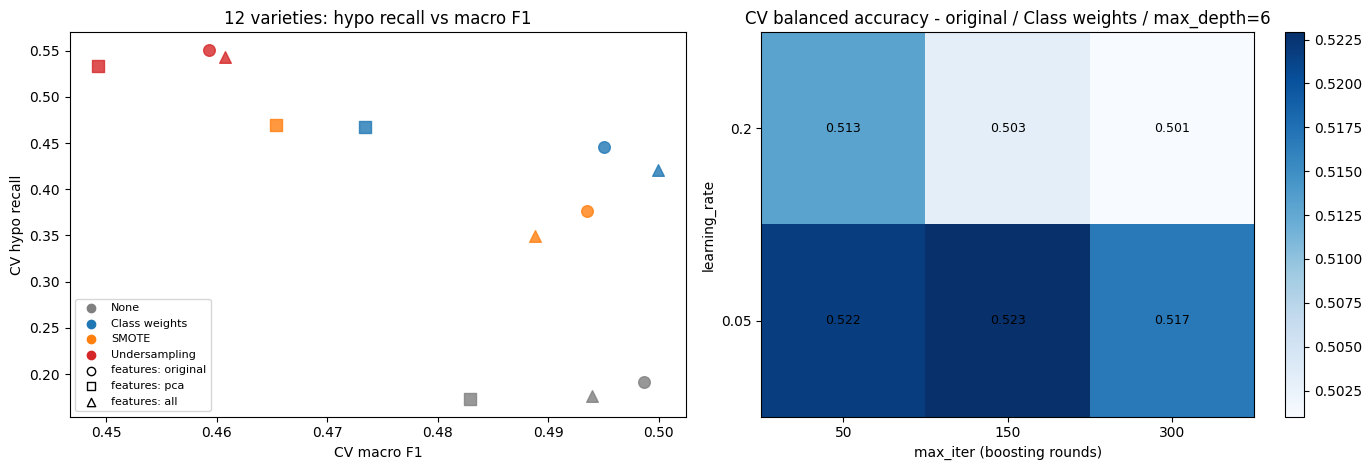

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# (a) hypo-recall vs macro-F1 for every variety - the trade-off the imbalance strategies create
markers = {"original": "o", "pca": "s", "all": "^"}
colors = {"None": "tab:gray", "Class weights": "tab:blue", "SMOTE": "tab:orange", "Undersampling": "tab:red"}
for _, r in varieties.iterrows():
    axes[0].scatter(r.macro_f1, r.hypo_recall, marker=markers[r.feature_set], color=colors[r.imbalance],
                    s=70, alpha=0.8)
for k, c in colors.items():
    axes[0].scatter([], [], color=c, label=k)
for k, m in markers.items():
    axes[0].scatter([], [], marker=m, color="white", edgecolor="black", label=f"features: {k}")
axes[0].set_xlabel("CV macro F1"); axes[0].set_ylabel("CV hypo recall")
axes[0].set_title(f"{len(varieties)} varieties: hypo recall vs macro F1")
axes[0].legend(fontsize=8, loc="best")

# (b) learning rate x rounds heat map for the chosen feature set / imbalance strategy / depth
sub = cv_all[(cv_all.feature_set == chosen.feature_set) & (cv_all.imbalance == chosen.imbalance) &
             (cv_all.depth == chosen.depth)]
grid_vals = sub.pivot(index="lr", columns="iters", values="mean_test_balanced_acc").sort_index(ascending=False)
im = axes[1].imshow(grid_vals.values, cmap="Blues", aspect="auto")
axes[1].set_xticks(range(grid_vals.shape[1])); axes[1].set_xticklabels([f"{c}" for c in grid_vals.columns])
axes[1].set_yticks(range(grid_vals.shape[0])); axes[1].set_yticklabels([f"{r:g}" for r in grid_vals.index])
for i in range(grid_vals.shape[0]):
    for j in range(grid_vals.shape[1]):
        axes[1].text(j, i, f"{grid_vals.values[i, j]:.3f}", ha="center", va="center", fontsize=9)
axes[1].set_xlabel("max_iter (boosting rounds)"); axes[1].set_ylabel("learning_rate")
axes[1].set_title(f"CV balanced accuracy - {chosen.feature_set} / {chosen.imbalance} / max_depth={chosen.depth}")
fig.colorbar(im, ax=axes[1])
plt.tight_layout(); plt.show()

### How many rounds? — the boosting-rounds experiment
Unlike a forest, a boosted model **can overfit as rounds are added**. The chosen configuration (same learning rate, tree
depth, features and imbalance strategy) is re-scored with 10 to 800 rounds, with the same 5 folds. The training score
keeps rising, while the validation score shows where extra rounds stop helping and start fitting noise.

 rounds  train  validation  validation std  train - validation gap
     10 0.5955      0.5017          0.0135                  0.0937
     25 0.6284      0.5139          0.0143                  0.1145
     50 0.6659      0.5217          0.0156                  0.1442
    100 0.7307      0.5256          0.0126                  0.2051
    200 0.8235      0.5221          0.0073                  0.3014
    400 0.9197      0.5130          0.0045                  0.4068
    800 0.9838      0.5041          0.0037                  0.4797


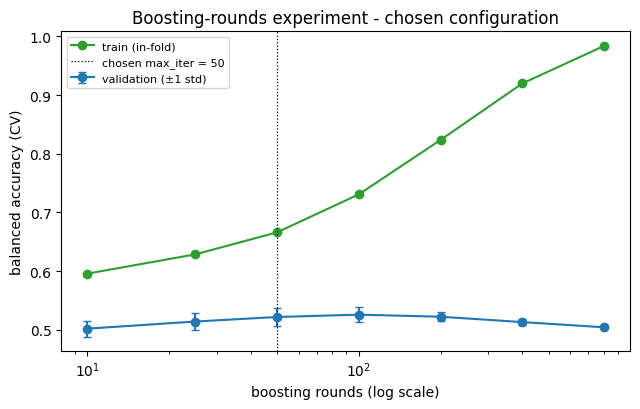

In [12]:
ROUNDS = [10, 25, 50, 100, 200, 400, 800]
rows = []
for n in ROUNDS:
    m = clone(pipe).set_params(**{**chosen_params, "clf__max_iter": n})
    r = cross_validate(m, train[FEATURES], y_train, cv=cv, scoring="balanced_accuracy", return_train_score=True, n_jobs=-1)
    rows.append({"rounds": n, "train": r["train_score"].mean(), "validation": r["test_score"].mean(),
                 "validation std": r["test_score"].std()})
rounds_curve = pd.DataFrame(rows)
rounds_curve["train - validation gap"] = rounds_curve["train"] - rounds_curve["validation"]
print(rounds_curve.round(4).to_string(index=False))

plt.figure(figsize=(6.5, 4.2))
plt.plot(rounds_curve.rounds, rounds_curve.train, marker="o", color="tab:green", label="train (in-fold)")
plt.errorbar(rounds_curve.rounds, rounds_curve.validation, yerr=rounds_curve["validation std"], marker="o",
             color="tab:blue", capsize=3, label="validation (±1 std)")
plt.axvline(chosen.iters, color="black", ls=":", lw=0.9, label=f"chosen max_iter = {chosen.iters}")
plt.xscale("log"); plt.xlabel("boosting rounds (log scale)"); plt.ylabel("balanced accuracy (CV)")
plt.title("Boosting-rounds experiment - chosen configuration"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## 7. Final model — refit on the full training set, evaluated once on the test set
The chosen configuration is rebuilt from its parameters, refit on all training rows, and evaluated on the test set.

Final model: original features, Class weights, learning_rate=0.05, max_iter=50, max_depth=6
Fitted model: 50 rounds x 3 trees per round = 150 small trees

               precision    recall  f1-score   support

Hyperglycemic      0.525     0.575     0.549       960
 Hypoglycemic      0.217     0.455     0.294       308
       Normal      0.700     0.484     0.572      1391

     accuracy                          0.513      2659
    macro avg      0.481     0.504     0.471      2659
 weighted avg      0.581     0.513     0.531      2659



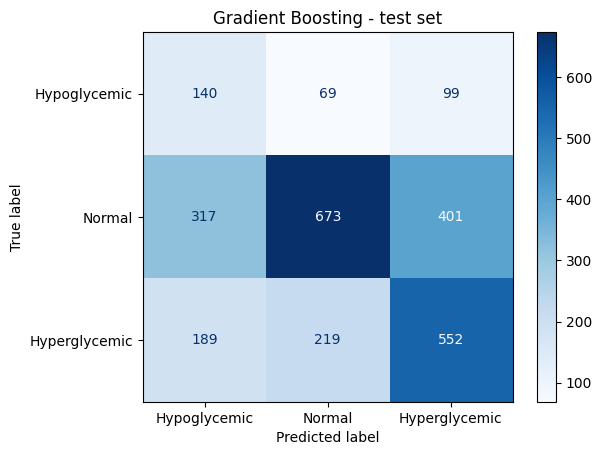

In [13]:
final_model = clone(pipe).set_params(**chosen_params).fit(train[FEATURES], y_train)
gb = final_model.named_steps["clf"]
print("Final model:", describe(chosen))
print(f"Fitted model: {gb.n_iter_} rounds x {gb.n_trees_per_iteration_} trees per round = {gb.n_iter_ * gb.n_trees_per_iteration_} small trees")

y_pred = final_model.predict(test[FEATURES])
print("\n" + classification_report(y_test, y_pred, digits=3))

LABELS = ["Hypoglycemic", "Normal", "Hyperglycemic"]
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=LABELS), display_labels=LABELS).plot(cmap="Blues")
plt.title("Gradient Boosting - test set"); plt.show()

In [14]:
final_row = {"model": "Gradient Boosting (tuned, chosen)", **test_metrics(y_test, y_pred)}

# Untuned model: scikit-learn defaults (100 rounds, learning rate 0.1, up to 31 leaves per tree), same 21 features,
# no imbalance handling, early stopping switched off so that it is comparable with the cross-validated fits
default_gb = HistGradientBoostingClassifier(early_stopping=False, random_state=RANDOM_STATE).fit(train[FEATURES], y_train)
default_row = {"model": "Gradient Boosting (untuned defaults)", **test_metrics(y_test, default_gb.predict(test[FEATURES]))}

SAVED = [("SVM RBF (Model 4, tuned)", "model_results_svm.csv"),
         ("Random Forest (Model 3, tuned)", "model_results_random_forest.csv"),
         ("Decision Tree (Model 2, tuned)", "model_results_decision_tree.csv"),
         ("Logistic Regression (Model 1, tuned)", "model_results_logistic_regression.csv")]
rows = [default_row, final_row]
for label, path in SAVED:
    try:   # saved by the Model 1-4 notebooks: same features, same protocol, same test set
        saved = pd.read_csv(f"../results/outputs/{path}").iloc[0]
        rows.append({"model": label, **{m: saved[m] for m in ["balanced_acc", "hypo_recall", "hypo_precision", "hypo_f2", "accuracy", "macro_f1"]}})
    except FileNotFoundError:
        print(f"({path} not found - run that notebook to add its row to this table.)")

comparison = pd.DataFrame(rows)
print(comparison[["model", "balanced_acc", "hypo_recall", "hypo_precision", "hypo_f2", "accuracy", "macro_f1"]]
      .round(3).to_string(index=False))

                               model  balanced_acc  hypo_recall  hypo_precision  hypo_f2  accuracy  macro_f1
Gradient Boosting (untuned defaults)         0.458        0.123           0.442    0.144     0.588     0.463
   Gradient Boosting (tuned, chosen)         0.504        0.455           0.217    0.373     0.513     0.471
            SVM RBF (Model 4, tuned)         0.507        0.523           0.216    0.407     0.495     0.462
      Random Forest (Model 3, tuned)         0.503        0.416           0.234    0.360     0.521     0.475
      Decision Tree (Model 2, tuned)         0.485        0.565           0.180    0.396     0.449     0.428
Logistic Regression (Model 1, tuned)         0.478        0.519           0.182    0.379     0.461     0.433


In [15]:
# What the hypo precision means in practice on the test set
n_alarms = int((y_pred == HYPO).sum())
n_true = int(((y_pred == HYPO) & (y_test == HYPO)).sum())
base_rate = (y_test == HYPO).mean()
alarm = {
    "hypo alarms raised":             n_alarms,
    "share of all readings flagged":  f"{n_alarms / len(y_test):.1%}",
    "real hypo events caught":        f"{n_true} of {int((y_test == HYPO).sum())}",
    "false alarms per real hypo":     f"{(n_alarms - n_true) / max(n_true, 1):.1f}",
    "precision vs base rate (lift)":  f"{(n_true / max(n_alarms, 1)) / base_rate:.2f}x",
}
print(pd.Series(alarm, name="value").to_frame().to_string())

                                    value
hypo alarms raised                    646
share of all readings flagged       24.3%
real hypo events caught        140 of 308
false alarms per real hypo            3.6
precision vs base rate (lift)       1.87x


### Comparing operating points — hypo recall at the same share of flagged readings
Hypo recall depends on how many readings a model chooses to flag, so a model that flags fewer readings can show lower
recall even when it ranks readings better. To compare like with like, this model's hypo probabilities are ranked and
the top share of readings is flagged, matching the share flagged by each earlier model at its own default rule. (The
test labels are used only to measure recall at flag rates fixed by the other models; nothing is tuned on the test set.)

In [16]:
proba = final_model.predict_proba(test[FEATURES])
classes = list(gb.classes_)
p_hypo = proba[:, classes.index(HYPO)]
is_hypo = (y_test == HYPO).values

def gb_recall_at(share):
    k = int(round(share * len(y_test)))
    return is_hypo[np.argsort(-p_hypo)[:k]].sum() / is_hypo.sum()

rows = [{"compared with": "Gradient Boosting itself (sanity check)", "share flagged": n_alarms / len(y_test),
         "that model's hypo recall": final_row["hypo_recall"],
         "boosting hypo recall at that share": gb_recall_at(n_alarms / len(y_test))}]
for label, path in SAVED:
    try:
        saved = pd.read_csv(f"../results/outputs/{path}").iloc[0]
        rows.append({"compared with": label, "share flagged": saved["test_flagged_share"],
                     "that model's hypo recall": saved["hypo_recall"],
                     "boosting hypo recall at that share": gb_recall_at(saved["test_flagged_share"])})
    except (FileNotFoundError, KeyError):
        print(f"({path} not found or lacks test_flagged_share - re-run that notebook to add its row.)")
matched = pd.DataFrame(rows)
print(matched.round(3).to_string(index=False))

                          compared with  share flagged  that model's hypo recall  boosting hypo recall at that share
Gradient Boosting itself (sanity check)          0.243                     0.455                               0.471
               SVM RBF (Model 4, tuned)          0.281                     0.523                               0.539
         Random Forest (Model 3, tuned)          0.205                     0.416                               0.422
         Decision Tree (Model 2, tuned)          0.364                     0.565                               0.646
   Logistic Regression (Model 1, tuned)          0.330                     0.519                               0.617


### ROC AUC — ranking quality, independent of the threshold
Precision and recall above depend on the default rule "predict the class with the highest probability". ROC AUC instead
asks how well the predicted probabilities *rank* readings. Each curve is one class against the other two.

Test ROC AUC - Hypoglycemic vs rest : 0.709
Test ROC AUC - macro one-vs-rest    : 0.701


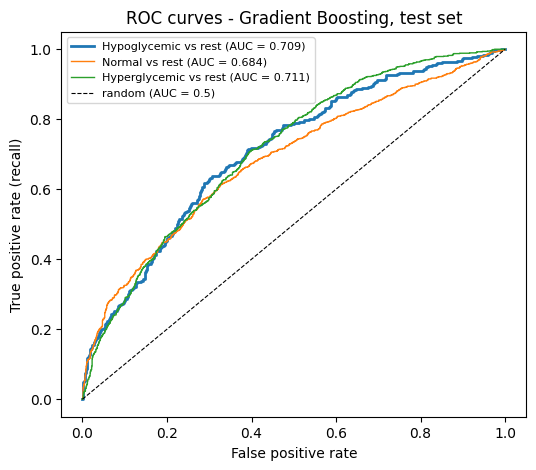

In [17]:
hypo_auc  = roc_auc_score((y_test == HYPO).astype(int), proba[:, classes.index(HYPO)])
macro_auc = roc_auc_score(y_test, proba, multi_class="ovr", average="macro", labels=classes)
print(f"Test ROC AUC - Hypoglycemic vs rest : {hypo_auc:.3f}")
print(f"Test ROC AUC - macro one-vs-rest    : {macro_auc:.3f}")

plt.figure(figsize=(6, 5))
for c in LABELS:
    fpr, tpr, _ = roc_curve((y_test == c).astype(int), proba[:, classes.index(c)])
    auc_c = roc_auc_score((y_test == c).astype(int), proba[:, classes.index(c)])
    plt.plot(fpr, tpr, label=f"{c} vs rest (AUC = {auc_c:.3f})", lw=2 if c == HYPO else 1)
plt.plot([0, 1], [0, 1], "k--", lw=0.8, label="random (AUC = 0.5)")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall)")
plt.title("ROC curves - Gradient Boosting, test set"); plt.legend(fontsize=8); plt.show()

### Choosing the hypo alarm threshold on training data
The default rule (predict the class with the highest probability or score) is not tuned for catching hypo events. Here the
alarm threshold is chosen from **out-of-fold** hypo scores on the **training set only** — the test set plays no part in
choosing it — for three recall targets, and each resulting rule is applied to the test set once. Which recall level is
acceptable is a clinical decision; the targets only show the trade-off between caught hypo events and false alarms.

In [18]:
score_method = "predict_proba" if hasattr(final_model, "predict_proba") else "decision_function"
hypo_col = list(final_model.classes_).index(HYPO)
oof_scores = cross_val_predict(clone(final_model), train[FEATURES], y_train, cv=cv, method=score_method)[:, hypo_col]
test_hypo_scores = getattr(final_model, score_method)(test[FEATURES])[:, hypo_col]
oof_is_hypo = (y_train == HYPO).values
test_is_hypo = (y_test == HYPO).values

default_flag = (y_pred == HYPO)
rows = [{"rule": "default (highest score wins)", "threshold": np.nan,
         "test hypo recall": test_is_hypo[default_flag].sum() / test_is_hypo.sum(),
         "test hypo precision": test_is_hypo[default_flag].sum() / max(default_flag.sum(), 1),
         "test share flagged": default_flag.mean()}]
order = np.argsort(-oof_scores)
cum_recall = np.cumsum(oof_is_hypo[order]) / oof_is_hypo.sum()
for target in [0.5, 0.6, 0.7]:
    tau = oof_scores[order][np.searchsorted(cum_recall, target)]
    flag = test_hypo_scores >= tau
    rows.append({"rule": f"threshold for out-of-fold recall {target}", "threshold": tau,
                 "test hypo recall": test_is_hypo[flag].sum() / test_is_hypo.sum(),
                 "test hypo precision": test_is_hypo[flag].sum() / max(flag.sum(), 1),
                 "test share flagged": flag.mean()})
threshold_table = pd.DataFrame(rows)
print(threshold_table.round(3).to_string(index=False))
threshold_table.assign(model=final_row["model"]).to_csv(
    "../results/outputs/threshold_analysis_" + str(final_row["model"]).split()[0].lower() + ".csv", index=False)

                                rule  threshold  test hypo recall  test hypo precision  test share flagged
        default (highest score wins)        NaN             0.455                0.217               0.243
threshold for out-of-fold recall 0.5      0.387             0.468                0.228               0.238
threshold for out-of-fold recall 0.6      0.334             0.591                0.217               0.316
threshold for out-of-fold recall 0.7      0.276             0.718                0.191               0.436


## 8. Overfitting check — training vs cross-validation vs test
Boosting fits the training data more closely with every round, so the gap between the training score and the
validation score is the thing to watch. Three scores are compared for the chosen configuration:
- **Train (in-fold):** average score on the training folds during cross-validation (data the model was fit on).
- **CV (validation):** average score on the held-out folds.
- **Test:** the final model on the test set.

The same comparison is made for the **untuned** model (scikit-learn defaults), to show what the tuning bought. The
boosting-rounds experiment in Section 6 shows how the gap opens as rounds are added.

In [20]:
fit_rows = ["balanced_acc", "hypo_recall", "macro_f1", "roc_auc_ovr"]
test_scores = {**test_metrics(y_test, y_pred), "roc_auc_ovr": macro_auc}
overfit = pd.DataFrame({
    "Train (in-fold)":  {m: chosen[f"mean_train_{m}"] for m in fit_rows},
    "CV (validation)":  {m: chosen[f"mean_test_{m}"] for m in fit_rows},
    "Test":             {m: test_scores[m] for m in fit_rows},
})
overfit["train - CV gap"] = overfit["Train (in-fold)"] - overfit["CV (validation)"]
print("Chosen (tuned) model:")
print(overfit.round(3).to_string())

# Untuned model: same folds, same scorers
u = cross_validate(clone(default_gb), train[FEATURES], y_train, cv=cv, scoring=scoring, return_train_score=True, n_jobs=-1)
default_test = {**test_metrics(y_test, default_gb.predict(test[FEATURES])),
                "roc_auc_ovr": roc_auc_score(y_test, default_gb.predict_proba(test[FEATURES]),
                                             multi_class="ovr", average="macro", labels=list(default_gb.classes_))}
overfit_default = pd.DataFrame({
    "Train (in-fold)":  {m: u[f"train_{m}"].mean() for m in fit_rows},
    "CV (validation)":  {m: u[f"test_{m}"].mean() for m in fit_rows},
    "Test":             {m: default_test[m] for m in fit_rows},
})
overfit_default["train - CV gap"] = overfit_default["Train (in-fold)"] - overfit_default["CV (validation)"]
print("\nUntuned model (defaults):")
print(overfit_default.round(3).to_string())

Chosen (tuned) model:
              Train (in-fold)  CV (validation)   Test  train - CV gap
balanced_acc            0.666            0.522  0.504           0.144
hypo_recall             0.760            0.505  0.455           0.254
macro_f1                0.597            0.481  0.471           0.116
roc_auc_ovr             0.832            0.702  0.701           0.130

Untuned model (defaults):
              Train (in-fold)  CV (validation)   Test  train - CV gap
balanced_acc            0.786            0.465  0.458           0.321
hypo_recall             0.596            0.113  0.123           0.483
macro_f1                0.825            0.469  0.463           0.356
roc_auc_ovr             0.965            0.712  0.709           0.253


## 9. Validation checks — does the row-wise split flatter the scores?
The split is row-wise, so all 70 patients appear in both train and test, and a patient's *later* readings can sit in
training while their *earlier* readings are validated. A model that fits its training data closely is the kind most
likely to benefit from that. Two extra checks, both on the training set only, re-score the chosen configuration:



In [21]:
# (a) Time-ordered: each patient's first 80% of readings train, last 20% validate
ordered = train.assign(ts=pd.to_datetime(train["timestamp"])).sort_values(["patient_id", "ts", "reading_index"])
position = ordered.groupby("patient_id").cumcount()
n_readings = ordered.groupby("patient_id")["patient_id"].transform("size")
is_late = position >= np.floor(n_readings * 0.8)
early, late = ordered[~is_late], ordered[is_late]
print(f"Time-ordered split: {len(early)} earlier readings train / {len(late)} later readings validate "
      f"({late.patient_id.nunique()} patients in both)")
print(pd.DataFrame({"earlier 80%": early[TARGET].value_counts(normalize=True),
                    "later 20%":   late[TARGET].value_counts(normalize=True)}).round(3), "\n")

time_model = clone(final_model).fit(early[FEATURES], early[TARGET])
scorers = {m: (get_scorer(v) if isinstance(v, str) else v) for m, v in scoring.items()}
time_scores = {m: scorers[m](time_model, late[FEATURES], late[TARGET]) for m in scoring}

# (b) Unseen-patient generalisation check: GroupKFold, validation patients never seen in training
group_cv = cross_validate(clone(final_model), train[FEATURES], y_train, groups=groups_train,
                          cv=GroupKFold(n_splits=5), scoring=scoring, n_jobs=-1)

check = pd.DataFrame({
    "Row-wise CV (used for tuning)":     {m: chosen[f"mean_test_{m}"] for m in scoring},
    "Time-ordered (monitored patients)": time_scores,
    "GroupKFold (unseen patients)":      {m: group_cv[f"test_{m}"].mean() for m in scoring},
})
check["time-ordered - row-wise"] = check["Time-ordered (monitored patients)"] - check["Row-wise CV (used for tuning)"]
check["unseen patients - row-wise"] = check["GroupKFold (unseen patients)"] - check["Row-wise CV (used for tuning)"]
print(check.round(3).to_string())

Time-ordered split: 8477 earlier readings train / 2158 later readings validate (70 patients in both)
                 earlier 80%  later 20%
next_risk_class                        
Normal                 0.519      0.540
Hyperglycemic          0.363      0.351
Hypoglycemic           0.117      0.109 

                Row-wise CV (used for tuning)  Time-ordered (monitored patients)  GroupKFold (unseen patients)  time-ordered - row-wise  unseen patients - row-wise
balanced_acc                            0.522                              0.561                         0.488                    0.039                      -0.034
hypo_f2                                 0.410                              0.453                         0.384                    0.043                      -0.026
hypo_recall                             0.505                              0.579                         0.486                    0.073                      -0.019
hypo_precision                          0

### Which features does the model depend on? — permutation importance
Each feature is shuffled in turn and the drop in balanced accuracy is measured. The model trained on each patient's
**earlier** readings is scored on their **later** readings, so this shows what it depends on for predicting the
future. A drop near zero means the feature is not needed for that prediction. The estimate is repeated 10 times per
feature, and the standard deviation shows how noisy it is. Only training-set rows are used, never the test set.
Highly correlated features share credit, so shuffling one at a time understates each.

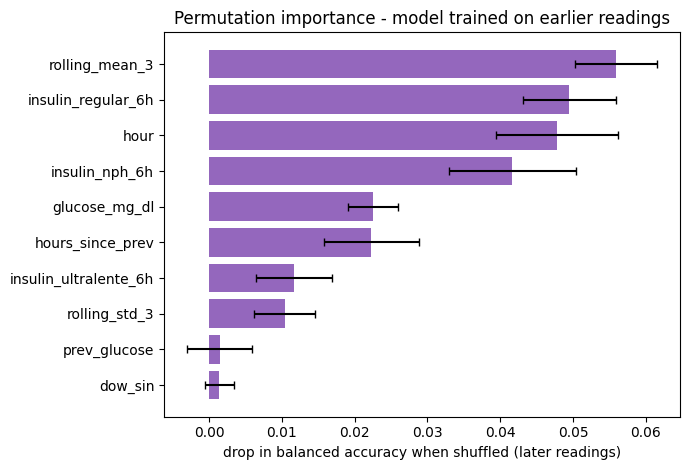

                       permutation drop     std
rolling_mean_3                   0.0559  0.0056
insulin_regular_6h               0.0495  0.0064
hour                             0.0478  0.0084
insulin_nph_6h                   0.0417  0.0087
glucose_mg_dl                    0.0225  0.0034
hours_since_prev                 0.0223  0.0065
insulin_ultralente_6h            0.0116  0.0052
rolling_std_3                    0.0104  0.0042
prev_glucose                     0.0014  0.0044
dow_sin                          0.0014  0.0020


In [22]:
perm = permutation_importance(time_model, late[FEATURES], late[TARGET], scoring="balanced_accuracy",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=1)
perm_imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)
perm_std = pd.Series(perm.importances_std, index=FEATURES)[perm_imp.index]
top_perm = perm_imp.head(10)

fig, ax = plt.subplots(figsize=(7, 4.8))
ax.barh(range(len(top_perm))[::-1], top_perm.values, xerr=perm_std[top_perm.index].values, color="tab:purple", capsize=3)
ax.set_yticks(range(len(top_perm))[::-1]); ax.set_yticklabels(top_perm.index)
ax.set_xlabel("drop in balanced accuracy when shuffled (later readings)")
ax.set_title("Permutation importance - model trained on earlier readings")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"permutation drop": top_perm.round(4), "std": perm_std[top_perm.index].round(4)}).to_string())

**`reading_index` is excluded from the features.** It is the reading's position in that patient's record (scaled), not a
physiological measurement. Pooled over patients, the hypo share can look as if it falls late in a record, but the two
tables below separate that pattern into its parts: **within** a patient's own record the hypo share barely moves, while
**between** patients it differs clearly, and the highest values of `reading_index` occur only in the patients with the
longest records. The feature therefore partly identifies *which patient* a reading comes from. In time-ordered validation
a patient's later readings receive larger `reading_index` values than any of their earlier ones, so a model that has
learned "large index = lower hypo risk" from the between-patient pattern is most consistent with under-predicting hypo on
future readings. In a separate audit on the training set, removing the feature raised time-ordered hypo recall at each of
three time cut points for each of the five models trained before KNN (15 of 15 comparisons), so it is excluded for all
six models. The sensitivity check at the end of Section 10 adds it back to this model.

In [23]:
ordered_ev = train.assign(ts=pd.to_datetime(train["timestamp"])).sort_values(["patient_id", "ts", "reading_index"])
n_ev = ordered_ev.groupby("patient_id")["patient_id"].transform("size")
ordered_ev["own_position"] = ordered_ev.groupby("patient_id").cumcount() / n_ev
ordered_ev["hypo_next"] = (ordered_ev[TARGET] == HYPO).astype(int)
ordered_ev["own_fifth"] = pd.cut(ordered_ev["own_position"], [0, 0.2, 0.4, 0.6, 0.8, 1.0], right=False,
                                 labels=["1st", "2nd", "3rd", "4th", "5th"])
print("WITHIN patients: share of readings whose NEXT reading is hypoglycemic, by fifth of that patient's own record")
print(ordered_ev.groupby("own_fifth", observed=True)["hypo_next"].mean().round(3).to_string())

per_patient = ordered_ev.groupby("patient_id").agg(readings=("hypo_next", "size"), hypo_share=("hypo_next", "mean"),
                                                   highest_index=("reading_index", "max"))
per_patient["record length"] = pd.qcut(per_patient["readings"], 3, labels=["short", "medium", "long"])
print("\nBETWEEN patients: by length of the patient's record")
print(per_patient.groupby("record length", observed=True).agg(
    patients=("readings", "size"), mean_readings=("readings", "mean"), hypo_share=("hypo_share", "mean"),
    mean_highest_reading_index=("highest_index", "mean")).round(3).to_string())

WITHIN patients: share of readings whose NEXT reading is hypoglycemic, by fifth of that patient's own record
own_fifth
1st    0.125
2nd    0.122
3rd    0.123
4th    0.102
5th    0.108

BETWEEN patients: by length of the patient's record
               patients  mean_readings  hypo_share  mean_highest_reading_index
record length                                                                 
short                24         66.833       0.179                      -0.089
medium               23         98.000       0.128                       0.104
long                 23        294.652       0.121                       1.427


## 10. Conclusion, limitations and improvements
*(Interpretation of the generated summary above; every number quoted there comes from this run.)*

**What mattered:**
1. **More rounds helped only up to a point — boosting can overfit, unlike a forest.** In the rounds experiment (chosen configuration) the validation balanced accuracy rises from 0.502 at 10 rounds to 0.526 at 100, then falls to 0.504 at 800, while the training score climbs from 0.596 to 0.984. The peak is broad: the competitive configurations in the grid used 50, 150 or 300 rounds, and 50 rounds (the fewest, picked by the preference order) scores within the noise of the 100-round peak.
2. **Small steps and moderately deep trees won.** In every variety that handles the imbalance, the best setting used the smaller learning rate (0.05) and the deeper trees (depth 6).
3. **Handling the imbalance helped, and class weights scored highest.** Without it the model flags few hypo readings (recall 0.180, though what it flags is right 42% of the time) and balanced accuracy is 0.482; with class weights 0.517, undersampling 0.505 and SMOTE 0.504. Boosting depends less on imbalance handling than the linear model does, but still gains from it.
4. **The original features are enough.** Original 0.514, all features 0.511 and PCA only 0.502 differ by about 1.5 fold-to-fold standard deviations (0.008), with PCA lowest.
5. **Tuning bought a better decision rule, not a better ranking.** The untuned model catches only 12% of hypo events at its default rule, but its test macro ROC AUC (0.709) is slightly higher than the tuned model's (0.701). I tuned on balanced accuracy, so a ranking metric could have picked different settings. The untuned model also memorises (train 0.786, validation 0.465).
6. **Performance relative to the other models.** Test balanced accuracy (0.504) is level with the Random Forest (0.503) and the SVM (0.507), and above the tree and the linear model. Macro ROC AUC (0.701) is level with the forest, above the SVM (0.672), tree (0.656) and linear model (0.652), and below KNN (0.727). At the same share of flagged readings it catches at least as many hypo events as each of the four earlier models (0.646 against 0.565, 0.617 against 0.519, 0.539 against 0.523 and 0.422 against 0.416). On unseen patients it scores 0.488, second only to KNN.

**Reading the model:**
- The fitted model is 150 small trees (50 rounds × 3 classes), so there are no rules to read. Permutation importance on later readings puts recent glucose (`rolling_mean_3`, 0.056) first, followed by `insulin_regular_6h`, time of day (`hour`), `insulin_nph_6h` and `glucose_mg_dl`. Correlated glucose features share credit, so each is understated.
- **`reading_index` sensitivity (Section 10).** Adding it back made the model worse on all five measures: row-wise CV 0.522 to 0.518, time-ordered balanced accuracy 0.561 to 0.536, time-ordered hypo recall 0.579 to 0.464, unseen-patient balanced accuracy 0.488 to 0.483 and unseen-patient hypo recall 0.486 to 0.458. Together with the Random Forest, this is the clearest support for excluding it.

**Validation checks.** Time-ordered balanced accuracy is 0.561 (+0.039 against the row-wise CV) and unseen-patient balanced accuracy is 0.488 (−0.034). The time-ordered figure is about 0.05 above a baseline that uses no features at all and only each patient's own earlier class frequencies (0.507; group comparison notebook).

**Overfitting check.** The in-fold training score (0.666) is well above the validation score (0.522), as expected for a model that keeps fitting its training data, and the test score (0.504) is 0.018 below the cross-validation score, about one fold-to-fold standard deviation. The untuned model's gap is more than twice as large (0.321).

**Limitations:**
- **The best learning rate is the smaller of only two tested.** A smaller one that was not tried might do as well or better, and the grid is coarse (two learning rates, three round counts, two depths).
- **Parameters left at their defaults:** `min_samples_leaf`, the L2 penalty and the leaf-count cap were not tuned, and early stopping was switched off so that every fit uses exactly the chosen number of rounds.
- **Tuned on balanced accuracy, not on ranking:** the untuned model ranks slightly better (see point 5).
- **Default rule misses over half of the hypo events** (it catches 45.5%). Reaching about 70% recall means flagging 44% of all readings, at roughly four false alarms per real hypo event.
- **Less readable than a single tree**, and the probabilities are not calibrated after class weights.
- **Validation for the use case.** The reviewed row-wise split is kept for tuning and testing. The time-ordered figure is the one to quote for future readings of monitored patients; it comes from a single holdout, so differences of a few hundredths are noise. The GroupKFold check shows generalisation to unseen patients.
- **Leakage handled:** `daily_total_insulin` and `reading_index` are excluded, PCA is re-fit inside the pipeline, and the `*_6h` windows were verified as backward-looking in the preprocessing code (they include events logged at the same timestamp as the reading; some timestamps are conventional slot times).
- **Test-set use during development:** nothing was chosen or tuned on the test set, but its results were viewed while the notebook was developed, and the threshold analysis and the matched-flag-rate table use test labels only to evaluate rules chosen on training data or at other models' flag rates.

**Improvements:**
- Use the alarm threshold from Section 7 for a clinically chosen recall instead of the default rule, and accept the stated number of false alarms.
- Tune on a ranking metric (log-loss or ROC AUC) and set the alarm threshold separately.
- Search smaller learning rates with early stopping, and tune `min_samples_leaf` and the L2 penalty.